In [34]:
from copy import copy

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

if torch.cuda.is_available():
    urzadzenie = torch.device("cuda")
elif torch.backends.mps.is_available():
    urzadzenie = torch.device("mps")
else:
    urzadzenie = torch.device("cpu")
print(f"Urządzenie: {urzadzenie}")



Urządzenie: mps


In [35]:
przeksztalcenie_testowe = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])
przeksztalcenie_treningowe = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    przeksztalcenie_testowe
])

zbior_treningowy = datasets.CIFAR10(
    root="./dane", train=True, download=True, transform=przeksztalcenie_treningowe
)
zbior_walidacyjny = copy(zbior_treningowy)
zbior_walidacyjny.transform = przeksztalcenie_testowe
zbior_testowy = datasets.CIFAR10(
    root="./dane", train=False, download=True, transform=przeksztalcenie_testowe
)

indeksy = torch.randperm(
    len(zbior_treningowy), generator=torch.Generator().manual_seed(42)
).tolist()
liczba_walidacyjna = 5000
indeksy_treningowe = indeksy[liczba_walidacyjna:]
indeksy_walidacyjne = indeksy[:liczba_walidacyjna]
ladowacz_treningowy = DataLoader(
    Subset(zbior_treningowy, indeksy_treningowe),
    batch_size=128,
    shuffle=True
)
ladowacz_walidacyjny = DataLoader(
    Subset(zbior_walidacyjny, indeksy_walidacyjne),
    batch_size=256
)
ladowacz_testowy = DataLoader(zbior_testowy, batch_size=256)

print(f"Liczba obrazów treningowych: {len(ladowacz_treningowy.dataset)}")
print(f"Liczba obrazów walidacyjnych: {liczba_walidacyjna}")
print(f"Liczba obrazów testowych: {len(zbior_testowy)}")




Liczba obrazów treningowych: 45000
Liczba obrazów walidacyjnych: 5000
Liczba obrazów testowych: 10000


## Przykładowe obrazy CIFAR-10

Przykłady z bieżącego zbioru treningowego.


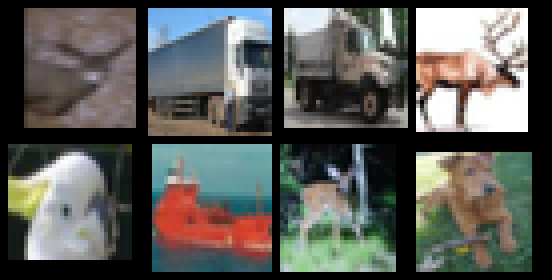

deer
truck
truck
deer
bird
ship
deer
dog


In [36]:
from IPython.display import display
from PIL import Image
from torchvision.utils import make_grid

srednie = torch.tensor((0.4914, 0.4822, 0.4465)).view(1, 3, 1, 1)
odchylenia = torch.tensor((0.2470, 0.2435, 0.2616)).view(1, 3, 1, 1)


def wyswietl_siatke(obrazy, opisy):
    obrazy = (obrazy.cpu() * odchylenia + srednie).clamp(0, 1)
    siatka = transforms.ToPILImage()(make_grid(obrazy, nrow=4, padding=2))
    display(siatka.resize((siatka.width * 4, siatka.height * 4), Image.Resampling.NEAREST))
    print("\n".join(opisy))


przyklady_podglad = [ladowacz_treningowy.dataset[indeks] for indeks in range(8)]
wyswietl_siatke(
    torch.stack([obraz for obraz, _ in przyklady_podglad]),
    [zbior_treningowy.classes[etykieta] for _, etykieta in przyklady_podglad]
)


In [37]:
class WarstwaHighway(nn.Module):
    def __init__(self, kanaly):
        super().__init__()
        self.przeksztalcenie = nn.Sequential(
            nn.Conv2d(kanaly, kanaly, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(kanaly),
            nn.ReLU(inplace=True)
        )
        self.brama = nn.Conv2d(kanaly, kanaly, kernel_size=1)
        nn.init.kaiming_normal_(
            self.przeksztalcenie[0].weight,
            mode="fan_out",
            nonlinearity="relu"
        )
        nn.init.constant_(self.brama.bias, -2.0)

    def forward(self, x):
        h = self.przeksztalcenie(x)
        t = torch.sigmoid(self.brama(x))
        return h * t + x * (1 - t)


class SiecHighway(nn.Module):
    def __init__(self):
        super().__init__()
        self.wejscie = nn.Sequential(
            nn.Conv2d(3, 24, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(24),
            nn.ReLU(inplace=True)
        )
        self.etap1 = nn.Sequential(*[WarstwaHighway(24) for _ in range(4)])
        self.przejscie1 = nn.Sequential(
            nn.Conv2d(24, 48, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(48),
            nn.ReLU(inplace=True)
        )
        self.etap2 = nn.Sequential(*[WarstwaHighway(48) for _ in range(4)])
        self.przejscie2 = nn.Sequential(
            nn.Conv2d(48, 96, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True)
        )
        self.etap3 = nn.Sequential(*[WarstwaHighway(96) for _ in range(3)])
        self.klasyfikator = nn.Linear(96, 10)

    def forward(self, x):
        x = self.wejscie(x)
        x = self.etap1(x)
        x = self.przejscie1(x)
        x = self.etap2(x)
        x = self.przejscie2(x)
        x = self.etap3(x)
        x = x.mean(dim=(2, 3))
        return self.klasyfikator(x)




In [38]:
def ocen_model(ladowacz):
    model.eval()
    poprawne = 0
    wszystkie = 0
    suma_strat = 0.0

    with torch.inference_mode():
        for obrazy, etykiety in ladowacz:
            wyniki = model(obrazy.to(urzadzenie))
            etykiety = etykiety.to(urzadzenie)
            suma_strat = suma_strat + funkcja_straty(wyniki, etykiety) * etykiety.size(0)
            poprawne = poprawne + (wyniki.argmax(dim=1) == etykiety).sum()
            wszystkie += etykiety.size(0)

    return suma_strat.item() / wszystkie, 100 * poprawne.item() / wszystkie




## Trening z walidacją



In [39]:
torch.manual_seed(42)
model = SiecHighway().to(urzadzenie)
funkcja_straty = nn.CrossEntropyLoss()
optymalizator = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4,
    nesterov=True
)
liczba_epok = 40
harmonogram = optim.lr_scheduler.CosineAnnealingLR(
    optymalizator,
    T_max=liczba_epok
)

print(f"Liczba parametrów: {sum(p.numel() for p in model.parameters()):,}")
najlepsza_dokladnosc = -1.0
najmniejsza_strata_walidacyjna = float("inf")
najlepsza_epoka = 0
najlepsze_wagi = None

for epoka in range(liczba_epok):
    model.train()
    suma_strat = 0.0
    liczba_obrazow = 0

    for obrazy, etykiety in ladowacz_treningowy:
        obrazy = obrazy.to(urzadzenie)
        etykiety = etykiety.to(urzadzenie)

        optymalizator.zero_grad(set_to_none=True)
        wyniki = model(obrazy)
        strata = funkcja_straty(wyniki, etykiety)
        strata.backward()
        optymalizator.step()
        suma_strat = suma_strat + strata.detach() * etykiety.size(0)
        liczba_obrazow += etykiety.size(0)

    harmonogram.step()
    srednia_strata = suma_strat.item() / liczba_obrazow
    strata_walidacyjna, dokladnosc_walidacyjna = ocen_model(ladowacz_walidacyjny)
    if (dokladnosc_walidacyjna, -strata_walidacyjna) > (
        najlepsza_dokladnosc, -najmniejsza_strata_walidacyjna
    ):
        najlepsza_dokladnosc = dokladnosc_walidacyjna
        najmniejsza_strata_walidacyjna = strata_walidacyjna
        najlepsza_epoka = epoka + 1
        najlepsze_wagi = {
            nazwa: wartosc.detach().clone()
            for nazwa, wartosc in model.state_dict().items()
        }

    print(
        f"Epoka {epoka + 1}/{liczba_epok}, "
        f"strata treningowa: {srednia_strata:.4f}, "
        f"strata walidacyjna: {strata_walidacyjna:.4f}, "
        f"dokładność walidacyjna: {dokladnosc_walidacyjna:.2f}%"
    )

model.load_state_dict(najlepsze_wagi)
torch.save(
    {nazwa: wartosc.cpu() for nazwa, wartosc in najlepsze_wagi.items()},
    "model_highway11_validated.pt"
)
strata_testowa, dokladnosc_testowa = ocen_model(ladowacz_testowy)
print(f"Najlepsza epoka walidacyjna: {najlepsza_epoka}")
print(f"Najlepsza dokładność walidacyjna: {najlepsza_dokladnosc:.2f}%")
print(f"Strata testowa: {strata_testowa:.4f}")
print(f"Dokładność testowa: {dokladnosc_testowa:.2f}%")


Liczba parametrów: 447,202
Epoka 1/40, strata treningowa: 1.5494, strata walidacyjna: 1.9458, dokładność walidacyjna: 37.44%
Epoka 2/40, strata treningowa: 1.0800, strata walidacyjna: 1.1859, dokładność walidacyjna: 58.50%
Epoka 3/40, strata treningowa: 0.8962, strata walidacyjna: 1.3402, dokładność walidacyjna: 58.90%
Epoka 4/40, strata treningowa: 0.7816, strata walidacyjna: 0.8193, dokładność walidacyjna: 72.92%
Epoka 5/40, strata treningowa: 0.6956, strata walidacyjna: 2.1959, dokładność walidacyjna: 48.56%
Epoka 6/40, strata treningowa: 0.6364, strata walidacyjna: 1.0449, dokładność walidacyjna: 70.24%
Epoka 7/40, strata treningowa: 0.5903, strata walidacyjna: 0.9739, dokładność walidacyjna: 68.84%
Epoka 8/40, strata treningowa: 0.5658, strata walidacyjna: 1.0406, dokładność walidacyjna: 68.12%
Epoka 9/40, strata treningowa: 0.5333, strata walidacyjna: 0.9978, dokładność walidacyjna: 69.46%
Epoka 10/40, strata treningowa: 0.5164, strata walidacyjna: 0.7816, dokładność walidacyjna:

## Przykłady poprawnych i błędnych predykcji na walidacji

Poprawne predykcje


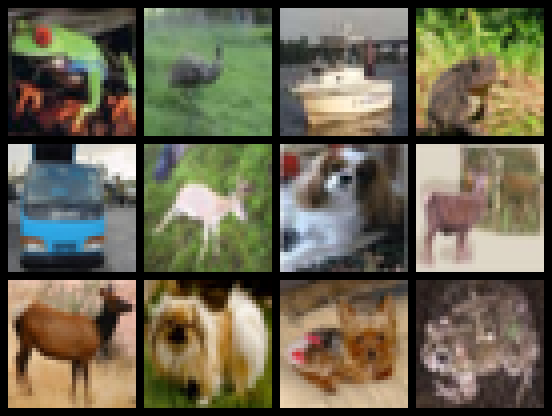

prawda: frog, model: frog (100.0%)
prawda: bird, model: bird (100.0%)
prawda: ship, model: ship (100.0%)
prawda: frog, model: frog (100.0%)
prawda: truck, model: truck (100.0%)
prawda: deer, model: deer (87.2%)
prawda: dog, model: dog (100.0%)
prawda: deer, model: deer (97.1%)
prawda: deer, model: deer (99.5%)
prawda: dog, model: dog (100.0%)
prawda: dog, model: dog (97.6%)
prawda: frog, model: frog (100.0%)
Błędne predykcje


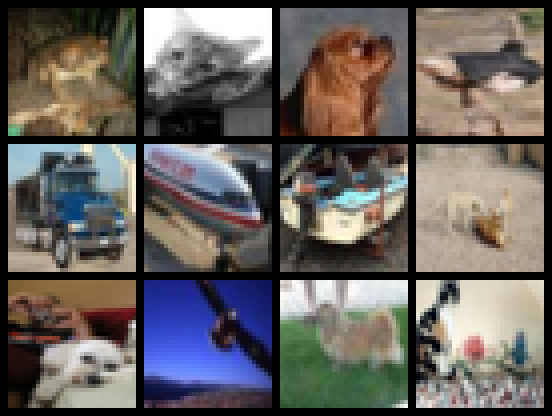

prawda: frog, model: deer (71.6%)
prawda: cat, model: bird (49.5%)
prawda: dog, model: frog (80.7%)
prawda: bird, model: deer (86.0%)
prawda: truck, model: automobile (79.7%)
prawda: airplane, model: ship (79.5%)
prawda: ship, model: airplane (38.7%)
prawda: cat, model: frog (79.8%)
prawda: dog, model: cat (98.3%)
prawda: bird, model: airplane (49.8%)
prawda: dog, model: cat (70.7%)
prawda: cat, model: airplane (42.0%)


In [40]:
def pokaz_przyklady(poprawne, limit=12):
    model.eval()
    przyklady = []

    with torch.inference_mode():
        for obrazy, etykiety in ladowacz_walidacyjny:
            wyniki = model(obrazy.to(urzadzenie))
            prawdopodobienstwa = torch.softmax(wyniki, dim=1).cpu()
            przewidywania = prawdopodobienstwa.argmax(dim=1)
            maska = (przewidywania == etykiety) == poprawne

            for indeks in maska.nonzero(as_tuple=True)[0].tolist():
                etykieta = int(etykiety[indeks])
                przewidywanie = int(przewidywania[indeks])
                pewnosc = float(prawdopodobienstwa[indeks, przewidywanie])
                przyklady.append((obrazy[indeks], etykieta, przewidywanie, pewnosc))
                if len(przyklady) == limit:
                    break
            if len(przyklady) == limit:
                break

    if not przyklady:
        print("Nie znaleziono takich przykładów na walidacji.")
        return

    print("Poprawne predykcje" if poprawne else "Błędne predykcje")
    wyswietl_siatke(
        torch.stack([przyklad[0] for przyklad in przyklady]),
        [
            f"prawda: {zbior_walidacyjny.classes[prawda]}, "
            f"model: {zbior_walidacyjny.classes[predykcja]} ({pewnosc:.1%})"
            for _, prawda, predykcja, pewnosc in przyklady
        ]
    )


pokaz_przyklady(poprawne=True)
pokaz_przyklady(poprawne=False)
